# TP3 — Fine-tuning Gemma 3 (4B) with LoRA on a Khmer Banking FAQ dataset

## 1. Installation

In [23]:
import os

if "COLAB_" in "".join(os.environ):
    !pip install -q --upgrade unsloth unsloth_zoo
else:
    !pip install -q unsloth
!pip install -q sacrebleu

In [24]:
import torch

assert torch.cuda.is_available(), "No GPU found."
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)

GPU: Tesla T4 | torch 2.14.1+cu130


## 2. Configuration

In [25]:
CONFIG = dict(
    model_name="unsloth/gemma-3-4b-it",
    max_seq_length=2048,
    load_in_4bit=True,

    r=16,
    lora_alpha=16,
    lora_dropout=0,

    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    num_train_epochs=3,
    warmup_steps=5,
    lr_scheduler_type="linear",
    weight_decay=0.01,
    optim="adamw_8bit",
    seed=3407,

    val_fraction=0.10,
    eval_steps=10,
    load_best_model_at_end=True,
    n_eval_generate=15,
)

DATA_PATH = "dataasilida_cleaned.csv"
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

## 3. Load Gemma 3 (4B) in 4-bit and attach LoRA adapters

In [26]:
from unsloth import FastModel
from unsloth.chat_templates import get_chat_template


def build_model(cfg):
    model, tokenizer = FastModel.from_pretrained(
        model_name=cfg["model_name"],
        max_seq_length=cfg["max_seq_length"],
        load_in_4bit=cfg["load_in_4bit"],
        load_in_8bit=False,
        full_finetuning=False,
    )
    model = FastModel.get_peft_model(
        model,
        finetune_vision_layers=False,
        finetune_language_layers=True,
        finetune_attention_modules=True,
        finetune_mlp_modules=True,
        r=cfg["r"],
        lora_alpha=cfg["lora_alpha"],
        lora_dropout=cfg["lora_dropout"],
        bias="none",
        random_state=cfg["seed"],
    )
    tokenizer = get_chat_template(tokenizer, chat_template="gemma-3")
    return model, tokenizer


model, tokenizer = build_model(CONFIG)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable LoRA parameters: {trainable:,} ({100 * trainable / total:.2f}% of {total:,})")

==((====))==  Unsloth 2026.11.4: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

## 4. Dataset preparation

### 4.1 Load and repair the CSV

In [27]:
import csv
import random
import re

import pandas as pd

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print(f"'{DATA_PATH}' not found -> please upload it")
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_PATH} next to this notebook")


def load_and_repair(path):
    with open(path, encoding="utf-8-sig") as f:
        rows = list(csv.reader(f))

    records, repaired, dropped = [], 0, 0
    for row in rows[1:]:
        if len(row) == 2:
            question, answer = row
        elif len(row) == 1 and "?" in row[0]:
            question, answer = row[0].split("?", 1)
            question, answer = question + "?", answer.lstrip(" ,")
            repaired += 1
        else:
            dropped += 1
            continue
        records.append({"input": question, "output": answer})
    return pd.DataFrame(records), repaired, dropped


raw_df, n_repaired, n_dropped = load_and_repair(DATA_PATH)
print(f"Rows read: {len(raw_df)} | repaired: {n_repaired} | dropped: {n_dropped}")

Rows read: 521 | repaired: 7 | dropped: 0


### 4.2 Clean the text

In [28]:
def clean_text(text):
    text = str(text).replace("\\n", "\n").replace("​", "")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    return text.strip()


df = raw_df.copy()
df["input"] = df["input"].map(clean_text)
df["output"] = df["output"].map(clean_text)

n_before = len(df)
df = df[(df.input.str.len() > 0) & (df.output.str.len() > 0)]
df = df.drop_duplicates(subset=["input", "output"]).reset_index(drop=True)
print(f"After cleaning: {len(df)} rows (removed {n_before - len(df)})")
print(f"Rows sharing a question with another row: {df.input.duplicated(keep=False).sum()}")

display(pd.DataFrame({"question": df.input.str.len().describe(),
                      "answer": df.output.str.len().describe()}).round(0))
df.sample(3, random_state=1)

After cleaning: 518 rows (removed 3)
Rows sharing a question with another row: 52


,question,answer
count,518.0,518.0
mean,61.0,321.0
std,27.0,303.0
min,16.0,20.0
25%,43.0,131.0
50%,56.0,228.0
75%,71.0,410.0
max,203.0,2802.0


,input,output
485,តើត្រូវចុះឈ្មោះប្រើប្រាស់សេវាសុវត្ថិភាព 3D អ៉ីអនដោយរបៀបណា,សេវាសុវត្ថិភាព 3D អ៉ីអនគឺមិនតម្រូវអោយមានការចុះឈ្មោះនោះទេ។ លោកអ្នក (ម្ចាស់អ៉ីអនកាត) នឹងទទួលបានលេខសម្ងាត់ម្តង ដែលមាន៦ខ្ទង់ដោយស្វ័យប្រវត្តិ នៅពេលលោកអ្នកធ្វើប្រតិបត្តិការអនឡាញជាមួយ អ៉ីអនកាត នៅលើគេហទំព...
273,តើលិខិតអះអាងលើគណនី និងព័ត៌មានអតិថិជនមានលក្ខណៈពិសេសយ៉ាងដូចម្តេច,អះអាងលើព័ត៌មានផ្សេងៗពាក់ព័ន្ធនឹងសេវាបញ្ញើសន្សំ សេវាឥណទាន សេវាបញ្ញើតាមរយៈប្រអប់សុវត្ថិភាពសេវា\nលិខិតធានា ឬកម្រិតបន្ទាត់ឥណទាន ជាដើម។\nទម្រង់លិខិតអាចប្រែប្រួលតាមតម្រូវការរបស់អតិថិជន។\nការអះអាងផ្អែកលើ...
420,ប្រសិនបើខ្ញុំបង់ប្រាក់រួចរាល់ហើយ តើខ្ញុំត្រូវប្រាប់ទៅផ្នែកផ្តល់សេវាអតិថិជនដែរឬទេ,ប្រសិនបើលោកអ្នកធ្វើការបង់ទឹកប្រាក់មុនថ្ងៃទី ៥ ជារៀងរាល់ខែ នោះលោកអ្នកពុំចំាបាច់ផ្តល់ដំណឹងមកផ្នែកផ្តល់សេវាអតិថិជនរបស់យើងខ្ញុំ អំពីការបង់ប្រាក់រួចរាល់នោះទេ។ ប៉ុន្តែ ប្រសិនបើលោកអ្នកមានការយឺតយ៉ាវក្នុងក...


### 4.3 Convert to the Gemma-3 chat format

In [29]:
def to_chat_text(question, answer):
    messages = [
        {"role": "user", "content": question},
        {"role": "assistant", "content": answer},
    ]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
    return text.removeprefix("<bos>")


df["text"] = [to_chat_text(q, a) for q, a in zip(df.input, df.output)]
print(df.text.iloc[0])

<start_of_turn>user
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី<end_of_turn>
<start_of_turn>model
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។<end_of_turn>



### 4.4 Check token lengths

In [30]:
text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)

df["n_tokens"] = [len(text_tokenizer(t, add_special_tokens=True)["input_ids"]) for t in df.text]
display(df.n_tokens.describe().round(0).to_frame("tokens per example"))

too_long = (df.n_tokens > CONFIG["max_seq_length"]).sum()
print(f"Examples longer than max_seq_length={CONFIG['max_seq_length']}: {too_long}")

df = df[df.n_tokens <= CONFIG["max_seq_length"]].reset_index(drop=True)
chars = (df.input.str.len() + df.output.str.len()).sum()
print("Chars per token (avg):", round(chars / df.n_tokens.sum(), 2))

,tokens per example
count,518.0
mean,195.0
std,145.0
min,42.0
25%,106.0
50%,149.0
75%,242.0
max,1256.0


Examples longer than max_seq_length=2048: 0
Chars per token (avg): 1.95


### 4.5 Train / validation split — grouped by question

In [31]:
from datasets import Dataset

rng = random.Random(CONFIG["seed"])
questions = sorted(df.input.unique())
rng.shuffle(questions)

n_val = max(1, round(CONFIG["val_fraction"] * len(questions)))
val_questions = set(questions[:n_val])

train_df = df[~df.input.isin(val_questions)].reset_index(drop=True)
val_df = df[df.input.isin(val_questions)].reset_index(drop=True)
assert not set(train_df.input) & set(val_df.input), "train/validation leakage"

train_dataset = Dataset.from_pandas(train_df[["text"]])
val_dataset = Dataset.from_pandas(val_df[["text"]])

effective_batch = CONFIG["per_device_train_batch_size"] * CONFIG["gradient_accumulation_steps"]
steps_per_epoch = -(-len(train_df) // effective_batch)
print(f"Train: {len(train_df)} examples | Validation: {len(val_df)} examples")
print(f"Steps per epoch: {steps_per_epoch} | Total steps: {steps_per_epoch * CONFIG['num_train_epochs']}")

Train: 466 examples | Validation: 52 examples
Steps per epoch: 59 | Total steps: 177


## 5. Baseline — answers before fine-tuning

In [32]:
def generate_answer(model, question, max_new_tokens=300, sample=False):
    messages = [{"role": "user", "content": [{"type": "text", "text": question}]}]
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    ).removeprefix("<bos>")
    inputs = tokenizer(text=[prompt], return_tensors="pt").to("cuda")

    gen_kwargs = dict(max_new_tokens=max_new_tokens, use_cache=True)
    if sample:
        gen_kwargs.update(do_sample=True, temperature=1.0, top_p=0.95, top_k=64)
    else:
        gen_kwargs.update(do_sample=False)

    with torch.no_grad():
        output = model.generate(**inputs, **gen_kwargs)
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return text_tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


eval_sample = val_df.sample(
    min(CONFIG["n_eval_generate"], len(val_df)), random_state=CONFIG["seed"]
).reset_index(drop=True)

FastModel.for_inference(model)
baseline_answers = []
for i, question in enumerate(eval_sample.input, start=1):
    baseline_answers.append(generate_answer(model, question))
    print(f"[{i}/{len(eval_sample)}] done")
eval_sample["before_finetune"] = baseline_answers
FastModel.for_training(model)

print("\nQ:", eval_sample.input[0])
print("Reference:", eval_sample.output[0][:300])
print("Base model:", baseline_answers[0][:300])

[1/15] done
[2/15] done
[3/15] done
[4/15] done
[5/15] done
[6/15] done
[7/15] done
[8/15] done
[9/15] done
[10/15] done
[11/15] done
[12/15] done
[13/15] done
[14/15] done
[15/15] done

Q: តើតម្រូវឲ្យមានឯកសារអ្វីខ្លះដើម្បីបើកគណនីអនាគតកុមារ
Reference: សម្រាប់កុមារ: ភ្ជាប់មកនូវសំបុត្រកំណើត ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬឯកសារសម្គាល់អត្តសញ្ញាណ ដែលចេញដោយអាជ្ញាធរមានសមត្ថកិច្ច។
សម្រាប់ឪពុក-ម្តាយ ឬអ្នកអាណាព្យាបាល
សម្រាប់ជនជាតិខ្មែរ
ត្រូវមានអត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬ ឯកសារបញ្ជាក់ពីអត្តសញ្ញាណ ដែលមានភ្ជាប
Base model: ដើម្បីបើកគណនីអនាគតកុមារ (Future Kids Account) នៅក្នុងប្រទេសកម្ពុជា នោះអ្នកត្រូវមានឯកសារ និងបំពេញលក្ខណៈតម្រូវការដូចខាងក្រោមនេះ:

**1. ឯកសារសំលេងលहरी (Identification Documents):**

*   **ឪពុកម្តាយ/អ្នកទទួលបន្ទុក:**
    *   บัตรបឋមភោគៈ (Primary ID Card) ឬบัตรបឋមភោគៈ 2 (Primary ID Card 2)
    *   លិខិតប


## 6. Build the trainer — SFT with a validation set

In [33]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported
from unsloth.chat_templates import train_on_responses_only


def build_trainer(model, cfg, output_dir):
    args = SFTConfig(
        output_dir=output_dir,
        dataset_text_field="text",
        per_device_train_batch_size=cfg["per_device_train_batch_size"],
        per_device_eval_batch_size=cfg["per_device_train_batch_size"],
        gradient_accumulation_steps=cfg["gradient_accumulation_steps"],
        num_train_epochs=cfg["num_train_epochs"],
        warmup_steps=cfg["warmup_steps"],
        learning_rate=cfg["learning_rate"],
        lr_scheduler_type=cfg["lr_scheduler_type"],
        weight_decay=cfg["weight_decay"],
        optim=cfg["optim"],
        fp16=not is_bfloat16_supported(),
        bf16=is_bfloat16_supported(),
        logging_steps=1,
        eval_strategy="steps",
        eval_steps=cfg["eval_steps"],
        save_strategy="steps",
        save_steps=cfg["eval_steps"],
        save_total_limit=2,
        save_only_model=True,
        load_best_model_at_end=cfg["load_best_model_at_end"],
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        seed=cfg["seed"],
        report_to="none",
        dataset_num_proc=2,
        packing=False,
    )
    trainer = SFTTrainer(
        model=model,
        processing_class=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        args=args,
    )
    return train_on_responses_only(
        trainer,
        instruction_part="<start_of_turn>user\n",
        response_part="<start_of_turn>model\n",
    )


trainer = build_trainer(model, CONFIG, output_dir="outputs_exp1")

Unsloth: Switching to float32 training since model cannot work with float16


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/466 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/52 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/466 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

**Verify the masking**

In [34]:
pad_id = text_tokenizer.pad_token_id


def show_masking(dataset, idx=0):
    input_ids = dataset[idx]["input_ids"]
    labels = dataset[idx]["labels"]
    kept = [t if label != -100 else pad_id for t, label in zip(input_ids, labels)]
    n_masked = sum(label == -100 for label in labels)

    print("FULL INPUT :", text_tokenizer.decode(input_ids)[:400])
    print("LOSS TOKENS:", text_tokenizer.decode(kept).replace(text_tokenizer.pad_token, "").strip()[:400])
    print(f"-> {n_masked}/{len(labels)} tokens masked\n")


print("=== train ===")
show_masking(trainer.train_dataset)
print("=== validation ===")
show_masking(trainer.eval_dataset)

=== train ===
FULL INPUT : <bos><start_of_turn>user
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី<end_of_turn>
<start_of_turn>model
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់
LOSS TOKENS: ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។<end_of_turn>
-> 37/208 tokens masked

=== validation ===
FULL INPUT : <bos><start_of_turn>user
តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បាន<end_of_turn>
<start_of_turn>model
លោកអ្នកអាចស

## 7. Train (Experiment 1 — main run)

In [35]:
gpu = torch.cuda.get_device_properties(0)
start_mem = round(torch.cuda.max_memory_reserved() / 1024**3, 3)
max_mem = round(gpu.total_memory / 1024**3, 3)
print(f"GPU = {gpu.name}. Max memory = {max_mem} GB. Reserved before training = {start_mem} GB.")

trainer_stats = trainer.train()

used_mem = round(torch.cuda.max_memory_reserved() / 1024**3, 3)
print(f"\nTraining time: {trainer_stats.metrics['train_runtime'] / 60:.1f} min")
print(f"Peak reserved memory = {used_mem} GB ({100 * used_mem / max_mem:.1f}% of GPU); "
      f"used for training = {used_mem - start_mem:.2f} GB")
print("Best checkpoint:", trainer.state.best_model_checkpoint,
      "| best validation loss:", trainer.state.best_metric)

GPU = Tesla T4. Max memory = 14.563 GB. Reserved before training = 9.207 GB.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 466 | Num Epochs = 3 | Total steps = 177
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,802,496 of 4,329,881,968 (0.69% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
10,2.132127,2.024945
20,1.760444,1.623052
30,1.614190,1.532901
40,1.303751,1.407731
50,1.339945,1.374095
60,1.287575,1.328133
70,1.264981,1.306669
80,1.240754,1.289222
90,1.058298,1.254081
100,0.934312,1.228708


Filter:   0%|          | 0/52 [00:00<?, ? examples/s]


Training time: 15.4 min
Peak reserved memory = 9.207 GB (63.2% of GPU); used for training = 0.00 GB
Best checkpoint: outputs_exp1/checkpoint-177 | best validation loss: 1.1771771907806396


## 8. Loss analysis

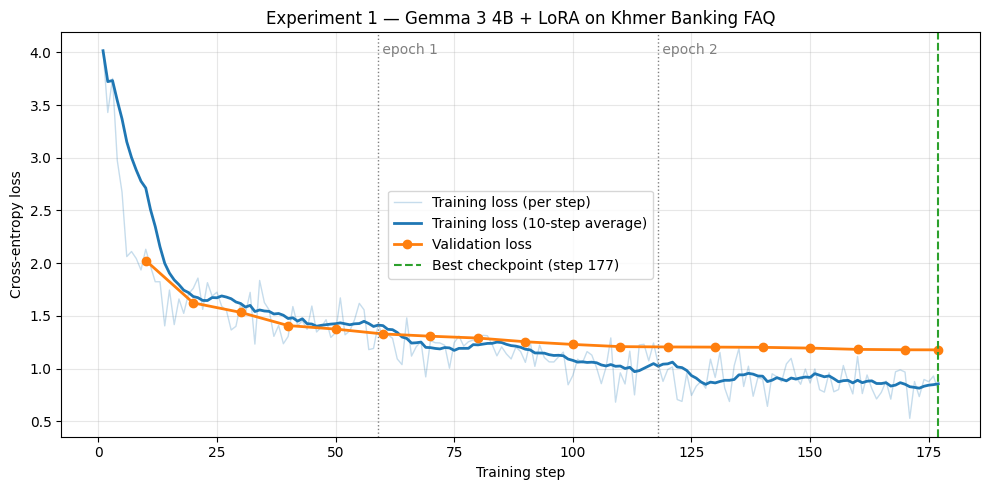

UNDERFITTING / not converged: validation loss is still decreasing at the end (1.177). Training longer (or a higher learning rate) should still help.


,Experiment 1
best_step,177
best_val_loss,1.1772
final_val_loss,1.1772
final_train_loss_smoothed,0.8547
gap,0.3225
val_rise_after_best_pct,0.0


In [36]:
import matplotlib.pyplot as plt
import numpy as np


def split_history(log_history):
    train_log = pd.DataFrame(
        [h for h in log_history if "loss" in h and "eval_loss" not in h]
    )[["step", "epoch", "loss"]]
    eval_log = pd.DataFrame(
        [h for h in log_history if "eval_loss" in h]
    )[["step", "epoch", "eval_loss"]]
    train_log["loss_smooth"] = train_log["loss"].rolling(10, min_periods=1).mean()
    return train_log, eval_log


def diagnose(train_log, eval_log, rise_tol=0.05):
    best_i = eval_log.eval_loss.idxmin()
    best_step = int(eval_log.step[best_i])
    best_loss = eval_log.eval_loss[best_i]
    final_val = eval_log.eval_loss.iloc[-1]
    final_train = train_log.loss_smooth.iloc[-1]
    rise = (final_val - best_loss) / best_loss

    last = eval_log.eval_loss.tail(3).values
    still_falling = len(last) == 3 and last[0] > last[1] > last[2]

    if rise > rise_tol:
        verdict = (f"OVERFITTING: validation loss was lowest at step {best_step} ({best_loss:.3f}) "
                   f"and then rose {100 * rise:.0f}% to {final_val:.3f} while training loss kept "
                   f"falling to {final_train:.3f}. Training after ~step {best_step} memorises the "
                   f"training answers instead of generalising.")
    elif still_falling:
        verdict = (f"UNDERFITTING / not converged: validation loss is still decreasing at the end "
                   f"({final_val:.3f}). Training longer (or a higher learning rate) should still help.")
    else:
        verdict = (f"GOOD FIT: validation loss flattened around {best_loss:.3f} "
                   f"(best at step {best_step}) with a train/val gap of {final_val - final_train:.3f}.")

    return dict(
        best_step=best_step,
        best_val_loss=round(best_loss, 4),
        final_val_loss=round(final_val, 4),
        final_train_loss_smoothed=round(final_train, 4),
        gap=round(final_val - final_train, 4),
        val_rise_after_best_pct=round(100 * rise, 1),
        verdict=verdict,
    )


def plot_losses(train_log, eval_log, title, path):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(train_log.step, train_log.loss, color="tab:blue", alpha=0.25, lw=1,
            label="Training loss (per step)")
    ax.plot(train_log.step, train_log.loss_smooth, color="tab:blue", lw=2,
            label="Training loss (10-step average)")
    ax.plot(eval_log.step, eval_log.eval_loss, "o-", color="tab:orange", lw=2,
            label="Validation loss")

    best = eval_log.eval_loss.idxmin()
    ax.axvline(eval_log.step[best], color="tab:green", ls="--", lw=1.5,
               label=f"Best checkpoint (step {int(eval_log.step[best])})")

    for epoch in range(1, int(np.ceil(train_log.epoch.max()))):
        step = train_log.loc[(train_log.epoch - epoch).abs().idxmin(), "step"]
        ax.axvline(step, color="gray", ls=":", lw=1)
        ax.text(step, ax.get_ylim()[1] * 0.95, f" epoch {epoch}", color="gray")

    ax.set(xlabel="Training step", ylabel="Cross-entropy loss", title=title)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


train_hist, eval_hist = split_history(trainer.state.log_history)
train_hist.to_csv(f"{RESULTS_DIR}/exp1_train_loss.csv", index=False)
eval_hist.to_csv(f"{RESULTS_DIR}/exp1_val_loss.csv", index=False)

plot_losses(train_hist, eval_hist,
            "Experiment 1 — Gemma 3 4B + LoRA on Khmer Banking FAQ",
            f"{RESULTS_DIR}/exp1_loss_curve.png")

diag1 = diagnose(train_hist, eval_hist)
print(diag1["verdict"])
pd.Series(diag1).drop("verdict").to_frame("Experiment 1")

In [37]:
eval_hist.assign(
    train_loss_smoothed=eval_hist.step.map(train_hist.set_index("step").loss_smooth),
    gap=lambda d: d.eval_loss - d.train_loss_smoothed,
).round(4)

,step,epoch,eval_loss,train_loss_smoothed,gap
0,10,0.1717,2.0249,2.7133,-0.6883
1,20,0.3433,1.6231,1.6836,-0.0606
2,30,0.5150,1.5329,1.6170,-0.0841
3,40,0.6867,1.4077,1.4745,-0.0668
4,50,0.8584,1.3741,1.4252,-0.0511
5,60,1.0172,1.3281,1.4069,-0.0788
6,70,1.1888,1.3067,1.1983,0.1084
7,80,1.3605,1.2892,1.2243,0.0650
8,90,1.5322,1.2541,1.1831,0.0709
9,100,1.7039,1.2287,1.0772,0.1515


## 9. Compare results

### 9.1 New dataset vs original dataset — training-loss curves

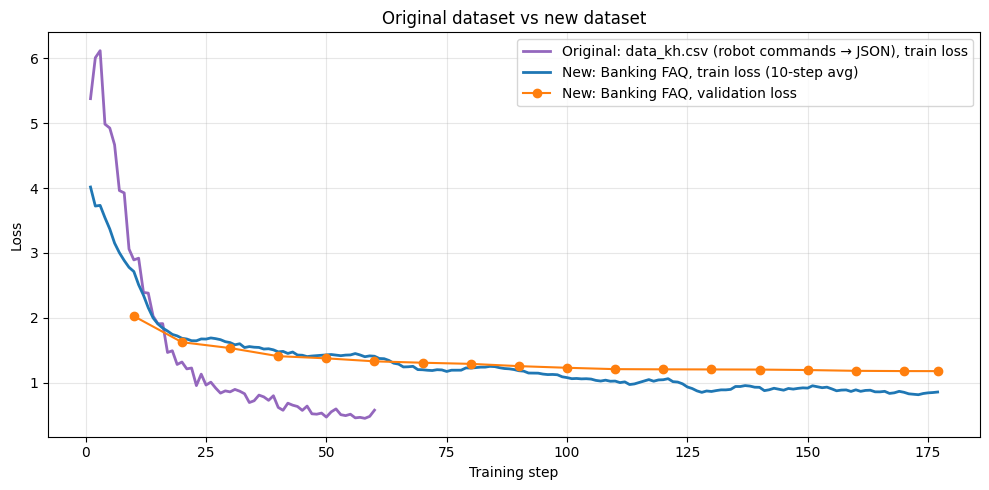

,Original (data_kh.csv),New (Banking FAQ)
task,Khmer command → JSON action,Khmer banking question → answer
train examples,2930,466
LoRA r / alpha,8 / 8,16 / 16
training,60 steps (16% of 1 epoch),3 epochs (177 steps)
validation set,none,52 examples
loss @ step 60,0.485,1.328
best val loss,n/a,1.1772


In [38]:
ORIGINAL_DATA_KH_LOSS = [
    5.3791, 6.0100, 6.1185, 4.9861, 4.9263, 4.6684, 3.9622, 3.9256, 3.0602, 2.8922,
    2.9186, 2.3912, 2.3802, 2.0256, 1.9073, 1.9099, 1.4648, 1.4912, 1.2801, 1.3175,
    1.2119, 1.2252, 0.9541, 1.1308, 0.9628, 1.0070, 0.9160, 0.8377, 0.8726, 0.8572,
    0.8951, 0.8677, 0.8285, 0.6928, 0.7205, 0.8073, 0.7801, 0.7268, 0.7975, 0.6175,
    0.5736, 0.6828, 0.6521, 0.6318, 0.5716, 0.6379, 0.5190, 0.5130, 0.5303, 0.4682,
    0.5486, 0.5945, 0.5055, 0.4909, 0.5126, 0.4564, 0.4642, 0.4490, 0.4791, 0.5751,
]
orig = pd.DataFrame({"step": range(1, 61), "loss": ORIGINAL_DATA_KH_LOSS})

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(orig.step, orig.loss, color="tab:purple", lw=2,
        label="Original: data_kh.csv (robot commands → JSON), train loss")
ax.plot(train_hist.step, train_hist.loss_smooth, color="tab:blue", lw=2,
        label="New: Banking FAQ, train loss (10-step avg)")
ax.plot(eval_hist.step, eval_hist.eval_loss, "o-", color="tab:orange",
        label="New: Banking FAQ, validation loss")
ax.set(xlabel="Training step", ylabel="Loss", title="Original dataset vs new dataset")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/dataset_comparison.png", dpi=150)
plt.show()

comparison = pd.DataFrame({
    "Original (data_kh.csv)": {
        "task": "Khmer command → JSON action",
        "train examples": 2930,
        "LoRA r / alpha": "8 / 8",
        "training": "60 steps (16% of 1 epoch)",
        "validation set": "none",
        "loss @ step 60": orig.loss.tail(5).mean().round(3),
        "best val loss": "n/a",
    },
    "New (Banking FAQ)": {
        "task": "Khmer banking question → answer",
        "train examples": len(train_df),
        "LoRA r / alpha": f"{CONFIG['r']} / {CONFIG['lora_alpha']}",
        "training": f"{CONFIG['num_train_epochs']} epochs ({int(train_hist.step.max())} steps)",
        "validation set": f"{len(val_df)} examples",
        "loss @ step 60": train_hist.loc[train_hist.step <= 60, "loss"].tail(5).mean().round(3),
        "best val loss": diag1["best_val_loss"],
    },
})
comparison.to_csv(f"{RESULTS_DIR}/dataset_comparison.csv")
comparison

### 9.2 Before vs after fine-tuning — answer quality on unseen validation questions

In [39]:
from sacrebleu.metrics import CHRF

chrf = CHRF()

FastModel.for_inference(model)
after_answers = []
for i, question in enumerate(eval_sample.input, start=1):
    after_answers.append(generate_answer(model, question))
    print(f"[{i}/{len(eval_sample)}] done")
eval_sample["after_finetune"] = after_answers

references = list(eval_sample.output)
eval_sample["chrF_before"] = [chrf.sentence_score(h, [r]).score
                              for h, r in zip(eval_sample.before_finetune, references)]
eval_sample["chrF_after"] = [chrf.sentence_score(h, [r]).score
                             for h, r in zip(eval_sample.after_finetune, references)]

corpus_before = chrf.corpus_score(list(eval_sample.before_finetune), [references]).score
corpus_after = chrf.corpus_score(list(eval_sample.after_finetune), [references]).score
print(f"\nCorpus chrF on {len(eval_sample)} unseen validation questions: "
      f"before = {corpus_before:.1f}   after = {corpus_after:.1f}")
print(f"Questions improved: {(eval_sample.chrF_after > eval_sample.chrF_before).sum()} / {len(eval_sample)}")
eval_sample.to_csv(f"{RESULTS_DIR}/before_after_answers.csv", index=False)

pd.set_option("display.max_colwidth", 200)
eval_sample[["input", "output", "before_finetune", "after_finetune", "chrF_before", "chrF_after"]].round(1)

[1/15] done
[2/15] done
[3/15] done
[4/15] done
[5/15] done
[6/15] done
[7/15] done
[8/15] done
[9/15] done
[10/15] done
[11/15] done
[12/15] done
[13/15] done
[14/15] done
[15/15] done

Corpus chrF on 15 unseen validation questions: before = 21.9   after = 29.4
Questions improved: 10 / 15


,input,output,before_finetune,after_finetune,chrF_before,chrF_after
0,តើតម្រូវឲ្យមានឯកសារអ្វីខ្លះដើម្បីបើកគណនីអនាគតកុមារ,សម្រាប់កុមារ: ភ្ជាប់មកនូវសំបុត្រកំណើត ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬឯកសារសម្គាល់អត្តសញ្ញាណ ដែលចេញដោយអាជ្ញាធរមានសមត្ថកិច្ច។\nសម្រាប់ឪពុក-ម្តាយ ឬអ្នកអាណាព្យាបាល\nសម្រាប់ជនជាតិខ្មែរ\nត្រូវម...,ដើម្បីបើកគណនីអនាគតកុមារ (Future Kids Account) នៅក្នុងប្រទេសកម្ពុជា នោះអ្នកត្រូវមានឯកសារ និងបំពេញលក្ខណៈតម្រូវការដូចខាងក្រោមនេះ:\n\n**1. ឯកសារសំលេងលहरी (Identification Documents):**\n\n* **ឪពុកម្ត...,ត្រូវមានឯកសារដូចខាងក្រោម៖\nលិខិតបញ្ជាក់អត្តសញ្ញាណសញ្ជាតិខ្មែរច្បាប់ដើម ឬលិខិតឆ្លងដែនច្បាប់ដើម ដែលនៅមានសុពលភាពយ៉ាងតិច បីខែ ឬច្បាប់ស្នាក់នៅ\nលិខិតបញ្ជាក់អត្តសញ្ញាណនៅកន្លែងបច្ចុប្បន្នស្នាក់នៅ (ដូចជា៖...,12.3,28.6
1,ចុះបើខ្ញុំភ្លេចលេខគណនីឥណទានរបស់ខ្ញុំ,សូមទំនាក់ទំនងមកកាន់លេខរបស់ ក្រុមការងារផ្នែកផ្តល់ព័ត៌មានអតិថិជនគឺ៖ 0២៣ ៩៩១ ៥៥៥/ ០៩៨ ៩៦១ ៩៦១/ 0១៧ ៩៩១ ៥៥៥ ឬតាមរយៈការផ្ញើសារទៅកាន់គេហទំព័រផ្លូវការរបស់ធនាគារឯកទេស ខេប៊ី ដេហាន របស់យើង។,"ប្រសិនបើអ្នកភ្លេចលេខសម្표គណនីឥណទានរបស់អ្នក អ្នកអាចធ្វើតាមវិធីសាស្រ្តដូចខាងក្រោមដើម្បីសក្ដានុបត្តិចុះ:\n\n1. **연락처 은행:** ទំនាក់ទំនងទៅធនាគារដែលអ្នកមានគណនីឥណទាន។ អ្នកអាចធ្វើដូច្នេះតាមរយៈលេខទូរស័ព្ទ, ...",សូមលោកអ្នកទំនាក់ទំនងមកកាន់ការិយាល័យទំនាក់ទំនងអតិថិជន ០២៣ ៩៨៨ ៥៥៥ ឬ ០១៥ ៩៨៨ ៥៥៥ ដើម្បីស្នើសុំពិនិត្យ និងទូទាត់សងប្រាក់។,20.8,22.4
2,តើឥណទាននេះមានប្រភេទរូបបិយប័ណ្ណ អ្វីខ្លះ,សម្រាប់ឥណទានអាជីវកម្មខ្នាតមធ្យម និងសាជីវកម្មផ្តល់ជូនដល់អតិថិជនជាប្រាក់រៀល ប្រាក់បាត និងប្រាក់ដុល្លារអាមេរិក។,ឥណទានមានប្រភេទរូបបិយប័ណ្ណជាច្រើនប្រភេទ ដែលអាចចែកចេញជាក្រុមធំៗ ៥ ក្រុម ដូចខាងក្រោមនេះ:\n\n1. **ឥណទានបញ្ជាក់ទ្រព្យ (Mortgage Loans):** ឥណទានប្រភេទនេះ ត្រូវបានប្រើប្រាស់ដើម្បីទិញ ឬស 건ស Buildings ដូច...,ឥណទាននេះមានប្រភេទរូបបិយប័ណ្ណជា៖ ប្រាក់រៀល ប្រាក់ដុល្លារអាមេរិក និងប្រាក់បាត។,17.5,42.7
3,តើខ្ញុំអាចដាក់ពាក្យស្នើសុំបង់រំលស់នៅកន្លែងណា,សូមធ្វើការដាក់ពាក្យស្នើសុំនៅតាមបណ្តាហាងដៃគូសហការរបស់យើងដែលមានស្លាកសញ្ញារបស់ ធនាគារឯកទេស អ៉ីអន (ខេមបូឌា) ភីអិលស៊ី ជាសម្គាល់។,អ្នកអាចដាក់ពាក្យស្នើសុំបង់រំលស់ឥណidays តាមរយៈកន្លែងជាច្រើន ដូចខាងក្រោម នេះ៖\n\n1. **សាខាបանկ:** ជាកន្លែងដែលអ្នកអាចដាក់ពាក្យស្នើសុំបង់រំលស់ឥណidays បានយ៉ាងច្រើនបំផុត។ អ្នកអាចទៅកាន់សាខាបանկដែលបានផ្ត...,លោកអ្នកអាចដាក់ពាក្យស្នើសុំបង់រំលស់នៅតាមការិយាល័យធនាគារឯកទេស អ៉ីអន (ខេមបូឌា) ភីអិលស៊ី ដែលស្ថិតនៅជិតលោកអ្នកបំផុត។,17.6,46.3
4,តើរបៀបសងត្រឡប់របស់ឥណទានពាណិជ្ជកម្មយ៉ាងដូចម្តេចដែរ,តម្រូវឲ្យសងការប្រាក់រៀងរាល់ខែ និងប្រាក់ដើមសងទៅតាមការព្រមព្រៀង។\nរាល់ការសងការ និងប្រាក់ដើមនៅចុងបញ្ចប់វដ្តនៃកម្ចី ត្រូវបានអនុញ្ញាតចំពោះ៖\nប្រភេទឥណទាន EBP ឬ OBL។\nសុវត្ថិភាពឥណទាន៖ ជាសាច់ប្រាក់ ប័ណ្ណស...,របៀបសងត្រឡប់របស់ឥណទានពាណិជ្ជកម្ម (Trade Credit Reconciliation) គឺសំខាន់ណាស់ ដើម្បីធានាថាបញ្ជីឥណទាន និងបញ្ជីបវិết (ledger) ត្រូវគ្នា និងមានភាពត្រឹមត្រូវ។ ខាងក្រោមនេះជាវិធីស 방법 ក្នុងការសងត្រឡប់ឥណទាន...,ការសងត្រឡប់របស់ឥណទានពាណិជ្ជកម្ម អាចធ្វើឡើងដូចខាងក្រោម៖\nសងរំលស់ប្រាក់ដើម និងសងការប្រាក់រៀងរាល់ខែ ។\nសងរំលស់ប្រាក់ដើមរៀងរាល់ខែ និងសងការប្រាក់នៅខែចុងឆ្នាំ ។\nសងរំលស់ប្រាក់ដើមរៀងរាល់ខែ និងសងការប្រាក់...,21.7,28.4
5,តើ អ៉ីអនវ៉លឡេត គឺជាអ្វី,អ៉ីអនវ៉លឡេត គឺជាកម្មវិធីទូទាត់តាមទូរស័ព្ទដៃបង្កើតឡើងដោយ ធនាគារឯកទេស អ៉ីអន (ខេមបូឌា) ភីអិលស៊ី ហៅកាត់ថា “ASB”។ ជាមួយអ៉ីអនវ៉លឡេត លោកអ្នកអាចធ្វើការទូទាត់ថ្លៃទំនិញ បង់វិក្កយប័ត្រ បញ្ចូលកាតទូរស័ព្ទ ឬ ផ្...,អ៉ីអនវ៉លឡេត (EAN) គឺជាលេខសម្គាល់លំអិត (Unique Identifier) ដែលត្រូវបានប្រើប្រាស់ដើម្បីស្វែងរកផលិតផល ក្នុងតំបន់អឺរ៉ុప్។ នេះជាការបកស្រាយយ៉ាងពេញលេញ៖\n\n* **EAN (European Article Number):** គឺជាប្រភេ...,អ៉ីអនវ៉លឡេតគឺជាកម្មវិធីបង់ថ្លៃទំនិញ-សេវាកម្មមួយប្រភេទ ដែលអនុញ្ញាតឲ្យអតិថិជនអាចទូទាត់ថ្លៃទំនិញ-សេវាកម្មតាមរយៈទូរសព្ទចល័ត ក្នុងរយៈកាលមួយថ្ងៃ ដោយមិនចាំបាច់យកសាច់ប្រាក់មកទូទាត់ ឬ ធ្វើការបង់ជាសាច់ប្រាក...,22.2,26.5
6,តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បាន,លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បានដោយគ្រាន់តែ បើកគណនីមួយនៅធនាគារ អេស៊ីលីដា សាខាណាមួយដែលនៅជិតលោកអ្នកបំផុត ហើយគណនីនោះអាចជា គណនីបញ្ញើសំចៃ គណនីតាមតម្រូវការ ឬគណនីចរន្ត បន្ទាប់មក...,ដើម្បីស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា នោះ ត្រូវធ្វើតាមលក្ខណៈ និងដំណើរការដូចខាងក្រោមនេះ៖\n\n**1. ធានាថាអ្នកមានលក្ខណៈបឋម:**\n\n* **អាយុ:** ត្រូវមានអាយុយ៉ាងน้อย ១៨ឆ្នាំ។\n* **ប្រជាជន:...,លោក-អ្នកអាចស្នើសុំប័ណ្ណឥណ

In [40]:
for i in range(min(3, len(eval_sample))):
    row = eval_sample.iloc[i]
    print(f"━━━━━━━━ Example {i + 1} ━━━━━━━━")
    print(f"QUESTION : {row.input}")
    print(f"REFERENCE: {row.output[:350]}")
    print(f"BEFORE   : {row.before_finetune[:350]}")
    print(f"AFTER    : {row.after_finetune[:350]}")
    print(f"chrF before {row.chrF_before:.1f} -> after {row.chrF_after:.1f}\n")

━━━━━━━━ Example 1 ━━━━━━━━
QUESTION : តើតម្រូវឲ្យមានឯកសារអ្វីខ្លះដើម្បីបើកគណនីអនាគតកុមារ
REFERENCE: សម្រាប់កុមារ: ភ្ជាប់មកនូវសំបុត្រកំណើត ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬឯកសារសម្គាល់អត្តសញ្ញាណ ដែលចេញដោយអាជ្ញាធរមានសមត្ថកិច្ច។
សម្រាប់ឪពុក-ម្តាយ ឬអ្នកអាណាព្យាបាល
សម្រាប់ជនជាតិខ្មែរ
ត្រូវមានអត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬ ឯកសារបញ្ជាក់ពីអត្តសញ្ញាណ ដែលមានភ្ជាប់នូវរូបថតរបស់សាមីខ្លួនដែលចេញផ្សាយដោយអាជ្ញាធរមានសមត
BEFORE   : ដើម្បីបើកគណនីអនាគតកុមារ (Future Kids Account) នៅក្នុងប្រទេសកម្ពុជា នោះអ្នកត្រូវមានឯកសារ និងបំពេញលក្ខណៈតម្រូវការដូចខាងក្រោមនេះ:

**1. ឯកសារសំលេងលहरी (Identification Documents):**

*   **ឪពុកម្តាយ/អ្នកទទួលបន្ទុក:**
    *   บัตรបឋមភោគៈ (Primary ID Card) ឬบัตรបឋមភោគៈ 2 (Primary ID Card 2)
    *   លិខិតបញ្ជាក់ថាជាឪពុកម្តាយ/អ្នកទទួលបន្ទុក (Letter of Guar
AFTER    : ត្រូវមានឯកសារដូចខាងក្រោម៖
លិខិតបញ្ជាក់អត្តសញ្ញាណសញ្ជាតិខ្មែរច្បាប់ដើម ឬលិខិតឆ្លងដែនច្បាប់ដើម ដែលនៅមានសុពលភាពយ៉ាងតិច បីខែ ឬច្បាប់ស្នាក់នៅ
លិខិតបញ្ជាក់អត្តសញ្ញាណនៅកន្លែងបច្ចុប្ប

### 9.3 Try your own question (live demo)

In [41]:
from transformers import TextStreamer

question = "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា មានសុពលភាពប៉ុន្មានឆ្នាំ"

messages = [{"role": "user", "content": [{"type": "text", "text": question}]}]
prompt = tokenizer.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
).removeprefix("<bos>")
inputs = tokenizer(text=[prompt], return_tensors="pt").to("cuda")

_ = model.generate(
    **inputs,
    max_new_tokens=300,
    do_sample=True,
    temperature=1.0,
    top_p=0.95,
    top_k=64,
    streamer=TextStreamer(text_tokenizer, skip_prompt=True, skip_special_tokens=True),
)

ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា មានសុពលភាពដល់ ៨ឆ្នាំ គិតពីថ្ងៃចេញ។


## 10. Save the fine-tuned LoRA adapter

In [42]:
model.save_pretrained("gemma3_banking_lora")
tokenizer.save_pretrained("gemma3_banking_lora")
print("Saved to ./gemma3_banking_lora")

Saved to ./gemma3_banking_lora


## 11. (Optional) Experiment 2 — hyperparameter comparison

In [43]:
import gc

RUN_EXPERIMENT_2 = False

if RUN_EXPERIMENT_2:
    CONFIG_2 = {**CONFIG, "learning_rate": 2e-5}

    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()

    model, tokenizer = build_model(CONFIG_2)
    trainer = build_trainer(model, CONFIG_2, output_dir="outputs_exp2")
    trainer.train()

    train_hist2, eval_hist2 = split_history(trainer.state.log_history)
    train_hist2.to_csv(f"{RESULTS_DIR}/exp2_train_loss.csv", index=False)
    eval_hist2.to_csv(f"{RESULTS_DIR}/exp2_val_loss.csv", index=False)
    diag2 = diagnose(train_hist2, eval_hist2)
    print(diag2["verdict"])

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(train_hist.step, train_hist.loss_smooth, color="tab:blue", lw=2,
            label="Exp 1 (lr=2e-4) train")
    ax.plot(eval_hist.step, eval_hist.eval_loss, "o-", color="tab:blue", alpha=0.6,
            label="Exp 1 (lr=2e-4) validation")
    ax.plot(train_hist2.step, train_hist2.loss_smooth, color="tab:red", lw=2,
            label="Exp 2 (lr=2e-5) train")
    ax.plot(eval_hist2.step, eval_hist2.eval_loss, "s-", color="tab:red", alpha=0.6,
            label="Exp 2 (lr=2e-5) validation")
    ax.set(xlabel="Training step", ylabel="Loss", title="Effect of learning rate")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/exp1_vs_exp2_learning_rate.png", dpi=150)
    plt.show()

    display(pd.DataFrame({"Exp 1 (lr=2e-4)": diag1, "Exp 2 (lr=2e-5)": diag2}).drop("verdict"))

## 12. Download all results (plots + CSVs)

In [44]:
import json
import shutil

with open(f"{RESULTS_DIR}/config_exp1.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
with open(f"{RESULTS_DIR}/diagnosis_exp1.json", "w") as f:
    json.dump(diag1, f, indent=2, ensure_ascii=False)

shutil.make_archive("tp3_results", "zip", RESULTS_DIR)
print(sorted(os.listdir(RESULTS_DIR)))

try:
    from google.colab import files
    files.download("tp3_results.zip")
except ImportError:
    print("Saved tp3_results.zip")

['before_after_answers.csv', 'config_exp1.json', 'dataset_comparison.csv', 'dataset_comparison.png', 'diagnosis_exp1.json', 'exp1_loss_curve.png', 'exp1_train_loss.csv', 'exp1_val_loss.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>